# Chapitre 3 - Cours 3 : B-trees, et la comparaison avec les arbres LSM

Ce notebook couvre la section *B-Trees* (avec *Making B-trees reliable* et *B-tree
optimizations*) puis la section *Comparing B-Trees and LSM-Trees* (*Advantages of
LSM-trees*, *Downsides of LSM-trees*). Nous implémentons un arbre B+ à pages
(`S.BPlusTree`), provoquons une panne au milieu d'un éclatement de page, puis comparons
mesures à l'appui le B-tree et le moteur LSM du cours 2.

**Plan.**

1. La structure d'un B-tree : pages, références, facteur de branchement.
2. Insertion et éclatement de pages ; hauteur logarithmique ; taux de remplissage.
3. Rendre un B-tree fiable : la panne au milieu d'un éclatement, et le WAL.
4. Quelques variantes : copie sur écriture, clés abrégées, feuilles chaînées.
5. Comparer B-trees et arbres LSM : lectures, écritures séquentielles ou aléatoires,
   amplification d'écriture, pics de latence, espace disque.

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)


def dessiner_btree(pages, root, ax, chemin=(), nouvelles=(), titre=None, couleur=INDIGO):
    """Dessine un arbre B+ : une boîte par page, les clés dedans, les liens vers les filles.
    `chemin` : pages surlignées (parcours d'une recherche) ; `nouvelles` : pages créées."""
    niveaux, front = [], [root]
    while front:
        niveaux.append(front)
        front = [c for pid in front if not pages[pid].leaf for c in pages[pid].children]
    pos, largeur = {}, {}
    feuilles = niveaux[-1]
    x = 0.0
    for pid in feuilles:
        w = 0.55 * max(1, len(pages[pid].keys)) + 0.3
        pos[pid], largeur[pid] = (x + w / 2, 0), w
        x += w + 0.35
    for depth in range(len(niveaux) - 2, -1, -1):
        y = len(niveaux) - 1 - depth
        for pid in niveaux[depth]:
            kids = pages[pid].children
            cx = (pos[kids[0]][0] + pos[kids[-1]][0]) / 2
            w = 0.55 * max(1, len(pages[pid].keys)) + 0.3
            pos[pid], largeur[pid] = (cx, y), w
    for pid, (cx, y) in pos.items():
        p = pages[pid]
        if not p.leaf:
            n = len(p.children)
            for j, c in enumerate(p.children):
                sx = cx - largeur[pid] / 2 + largeur[pid] * (j + 0.5) / n
                tx, ty = pos[c]
                on = pid in chemin and c in chemin
                ax.plot([sx, tx], [y - 0.22, ty + 0.22], color=AMBER if on else "#CBD5E1",
                        lw=2.2 if on else 1, zorder=1)
    for pid, (cx, y) in pos.items():
        p = pages[pid]
        surl = pid in chemin
        neuf = pid in nouvelles
        fc = LIGHT[AMBER] if surl else (LIGHT[TEAL] if neuf else LIGHT[couleur])
        ec = AMBER if surl else (TEAL if neuf else couleur)
        ax.add_patch(plt.Rectangle((cx - largeur[pid] / 2, y - 0.22), largeur[pid], 0.44, facecolor=fc,
                                   edgecolor=ec, lw=1.8 if surl or neuf else 1.2, zorder=2))
        ax.text(cx, y, "  ".join(str(k) for k in p.keys), ha="center", va="center", fontsize=8.5,
                color=SLATE, zorder=3, fontweight="bold" if not p.leaf else "normal")
        ax.text(cx - largeur[pid] / 2, y + 0.3, f"p{pid}", fontsize=7, color=GRAY, zorder=3)
    for a, b in zip(feuilles, feuilles[1:]):
        ax.annotate("", xy=(pos[b][0] - largeur[b] / 2, -0.32), xytext=(pos[a][0] + largeur[a] / 2, -0.32),
                    arrowprops=dict(arrowstyle="-|>", color=GRAY, lw=0.8))
    ax.set_xlim(-0.3, x)
    ax.set_ylim(-0.6, len(niveaux) - 0.4)
    ax.axis("off")
    if titre:
        ax.set_title(titre)
    return pos

## 1. La structure d'un B-tree (section *B-Trees*)

**Une autre philosophie.** Les moteurs à journal découpent la base en segments de
taille variable, écrits une fois puis immuables. Le **B-tree** (1970, qualifié
d'« ubiquitaire » moins de dix ans plus tard) découpe au contraire la base en **pages
de taille fixe** (traditionnellement 4 Kio ; 8 Kio pour PostgreSQL, 16 Kio pour MySQL)
et **réécrit une page en place**. C'est la structure d'index standard de presque toutes
les bases relationnelles.

Chaque page a un **numéro** ; une page peut en désigner une autre par ce numéro, comme
un pointeur mais sur disque (l'offset dans le fichier vaut numéro × taille de page). On
construit ainsi un arbre :

- la **racine** est le point de départ de toute recherche ;
- une page **interne** contient des clés et des références vers des pages filles ;
  chaque fille est responsable d'un **intervalle continu** de clés, et les clés de la
  page mère en marquent les frontières ;
- les **feuilles** contiennent les clés individuelles, avec la valeur ou une référence
  vers elle.

Le nombre de références vers des filles dans une page est le **facteur de branchement**
(plusieurs centaines en pratique). Pour notre dessin, des pages de 4 clés au plus.

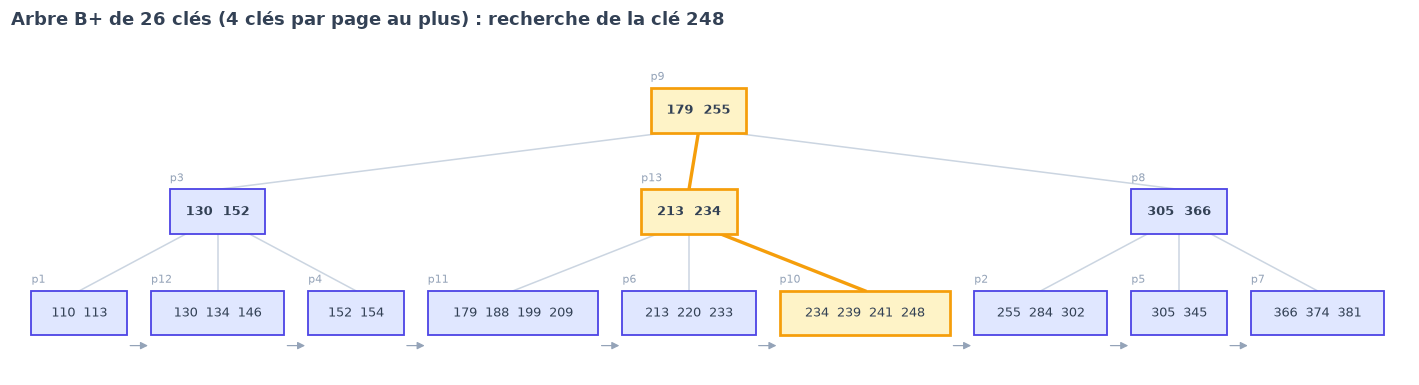

pages lues : p9 [179, 255] -> p13 [213, 234] -> p10 [234, 239, 241, 248]


In [2]:
arbre = S.BPlusTree(max_keys=4)
for k in random.Random(4).sample(range(100, 400), 26):
    arbre.insert(k, f"val{k}")
cible = sorted(k for k, _ in arbre.items())[17]
chemin = [pid for pid, _ in arbre.lookup_path(cible)]
fig, ax = plt.subplots(figsize=(13, 3.6))
dessiner_btree(arbre.pages, arbre.root, ax, chemin=chemin,
               titre=f"Arbre B+ de {len(arbre)} clés (4 clés par page au plus) : recherche de la clé {cible}")
plt.tight_layout(); plt.show()
print("pages lues :", " -> ".join(f"p{pid} {keys}" for pid, keys in arbre.lookup_path(cible)))

La recherche part de la racine, choisit à chaque niveau la référence dont l'intervalle
contient la clé (une recherche dichotomique dans la page) et descend jusqu'à la
feuille : **une page lue par niveau**. Les flèches grises sous les feuilles sont des
références vers la feuille voisine, utiles pour les parcours d'intervalle (section 4).

> **À retenir.** Un B-tree est un arbre de pages de taille fixe, triées par clé ; chaque
> page interne découpe son intervalle de clés entre ses filles. Une recherche lit une
> page par niveau.